# 04 · Sentiment des avis clients

**Question métier (Service client)** : que disent les clients dans leurs avis ?

**Étiquettes** : il n'y a pas d'annotation manuelle, donc on utilise la note laissée avec le texte. Une note de 4 ou 5 vaut **positif**, une note de 1 ou 2 vaut **négatif**. La note 3, ambiguë, est écartée.

**Stratégie linguistique : entraînement direct sur le portugais.** Trois options étaient possibles :

| Option | Pour | Contre |
|---|---|---|
| Traduire vers l'anglais | Accès aux modèles anglais | Coût d'API, latence, bruit sur l'argot et les fautes, données clients envoyées à un tiers (RGPD) |
| Modèle multilingue (BERT) | État de l'art | Lourd (plus de 500 Mo), lent sur CPU, image Docker volumineuse |
| **Entraînement direct** | 39 000 avis du domaine, rapide, léger, données gardées en interne | Il faut des étiquettes, mais les notes en tiennent lieu |

Le code est dans [`sentiment.py`](../src/shoppulse/sentiment.py) pour la baseline et dans [`sentiment_nn.py`](../src/shoppulse/sentiment_nn.py) pour le réseau PyTorch.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import learning_curve, train_test_split

from shoppulse.db import get_engine
from shoppulse.sentiment import baseline_model, load_reviews, normalize, top_terms
from shoppulse.sentiment_nn import train_network

plt.rcParams.update({"figure.figsize": (11, 3.5), "axes.grid": True, "grid.alpha": 0.3})
reviews = load_reviews(get_engine())
reviews["words"] = reviews["text"].map(lambda t: len(normalize(t).split()))
print(f"{len(reviews):,} avis étiquetés, {1 - reviews['label'].mean():.0%} négatifs")
print(f"Longueur médiane : {reviews['words'].median():.0f} mots")
reviews.sample(5, random_state=1)[["review_score", "text"]]

39,044 avis étiquetés, 28% négatifs
Longueur médiane : 8 mots


,review_score,text
27096,1,"Eu estou puto dá vida, pois comprei uma creati..."
25843,1,Entregue na data prevista.
27964,5,super recomendo
32967,5,Ótimo produto excelente qualidade entrega rápida.
33210,5,precisão Que lindo meus lustres...Eu recomendo


**Protocole** : on sépare un jeu de **test de 20 %**, stratifié et jamais utilisé pour les choix de modèle. Les 80 % restants servent à l'entraînement. Le réseau en garde 15 % pour sa validation (arrêt précoce et courbes).

In [2]:
train, test = train_test_split(
    reviews, test_size=0.2, stratify=reviews["label"], random_state=42
)
fit, val = train_test_split(
    train, test_size=0.15, stratify=train["label"], random_state=42
)


def scores(y: pd.Series, proba: np.ndarray) -> dict[str, float]:
    pred = proba >= 0.5
    return {
        "f1_macro": f1_score(y, pred, average="macro"),
        "roc_auc": roc_auc_score(y, proba),
        "rappel_négatifs": recall_score(y, pred, pos_label=0),
        "précision_négatifs": precision_score(y, pred, pos_label=0),
    }


print(len(fit), len(val), len(test))

26549 4686 7809


## 1. Baseline : TF-IDF + régression logistique

In [3]:
start = time.perf_counter()
baseline = baseline_model().fit(train["text"], train["label"])
baseline_time = time.perf_counter() - start
baseline_proba = baseline.predict_proba(test["text"])[:, 1]
pd.Series(scores(test["label"], baseline_proba)).round(3).to_frame("baseline")

,baseline
f1_macro,0.927
roc_auc,0.978
rappel_négatifs,0.938
précision_négatifs,0.858


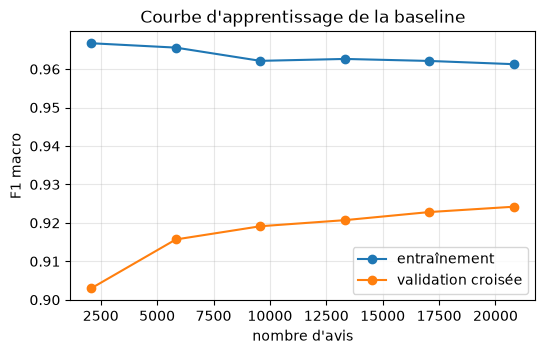

In [4]:
sizes, train_scores, val_scores = learning_curve(
    baseline_model(),
    train["text"],
    train["label"],
    cv=3,
    scoring="f1_macro",
    train_sizes=np.linspace(0.1, 1, 6),
    n_jobs=-1,
)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(sizes, train_scores.mean(axis=1), marker="o", label="entraînement")
ax.plot(sizes, val_scores.mean(axis=1), marker="o", label="validation croisée")
ax.set(
    title="Courbe d'apprentissage de la baseline",
    xlabel="nombre d'avis",
    ylabel="F1 macro",
)
ax.legend()

In [5]:
top_terms(baseline)

,négatif,positif
0,nao,recomendo
1,nao recomendo,parabens
2,pessimo,amei
3,pessima,lindo
4,comprei,rapida
5,ruim,satisfeito
6,nem,antes
7,quebrado,so nao
8,nao gostei,muito bom
9,nao recebi,adorei


**Lecture** :

- **Performance** : la baseline est déjà très bonne. Son F1 macro est de **0,927**, et elle détecte 94 % des avis négatifs. Quand elle prédit « négatif », elle a raison 86 % du temps.
- **Courbe d'apprentissage** : le score de validation monte encore légèrement avec plus de données (de 0,90 à 0,92), et l'écart avec l'entraînement se réduit. Plus de données aiderait un peu, mais le modèle est proche de son plafond.
- **Termes appris** : ils sont lisibles et cohérents, ce qui confirme qu'il ne fallait pas retirer les mots vides.
    - Côté négatif, on trouve **« não »**, « não recomendo », « não recebi », « péssimo », « quebrado » et « demora ».
    - Côté positif, on trouve « recomendo », « parabéns », « amei », « rápida » et « no prazo ».
    - « comprei » est négatif, car les plaintes racontent l'achat (« comprei X e não chegou »).

## 2. Réseau de neurones (PyTorch)

**Architecture** (type fastText) :

1. un embedding de 64 dimensions pour chaque mot et bigramme, dont on fait la **moyenne** ;
2. une couche cachée de 32 neurones avec activation ReLU et un dropout de 0,3 ;
3. une sortie logistique.

**Entraînement** : perte pondérée contre le déséquilibre, optimiseur Adam, 12 époques. On garde **l'époque de plus faible perte de validation** (arrêt précoce).

Meilleure époque : 5 ; vocabulaire : 26,908 tokens


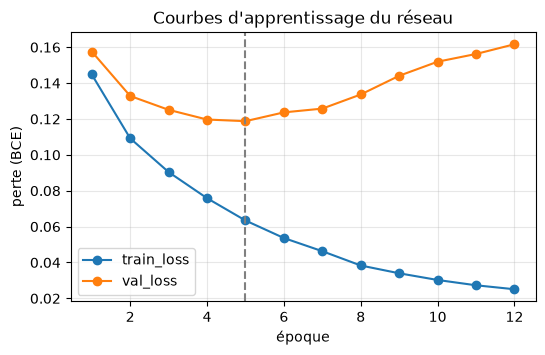

In [6]:
start = time.perf_counter()
network = train_network(
    list(fit["text"]), list(fit["label"]), list(val["text"]), list(val["label"])
)
network_time = time.perf_counter() - start
network_proba = network.predict_proba(list(test["text"]))
ax = network.history.plot(
    marker="o", title="Courbes d'apprentissage du réseau", figsize=(6, 3.5)
)
ax.set(xlabel="époque", ylabel="perte (BCE)")
best = network.history["val_loss"].idxmin()
ax.axvline(best, color="grey", ls="--")
print(f"Meilleure époque : {best} ; vocabulaire : {len(network.vocab):,} tokens")

**Lecture des courbes** : la perte d'entraînement baisse sans cesse, mais la perte de validation remonte **après l'époque 5**. C'est un **sur-apprentissage**, causé par les 27 000 tokens du vocabulaire, que le réseau mémorise. L'arrêt précoce retient l'époque 5.

## 3. Comparaison sur le jeu de test

In [7]:
comparison = pd.DataFrame(
    {
        "TF-IDF + rég. logistique": scores(test["label"], baseline_proba),
        "réseau PyTorch": scores(test["label"], network_proba),
    }
).T
comparison["entraînement_s"] = [baseline_time, network_time]
comparison.round(3)

,f1_macro,roc_auc,rappel_négatifs,précision_négatifs,entraînement_s
TF-IDF + rég. logistique,0.927,0.978,0.938,0.858,0.613
réseau PyTorch,0.923,0.976,0.949,0.843,16.967


**Choix : la baseline TF-IDF + régression logistique est servie en production.**

- **Performance** : les deux modèles sont **à égalité** (F1 macro de 0,927 contre 0,923, AUC de 0,978 contre 0,976). Le réseau détecte un peu plus de négatifs (95 % contre 94 %), au prix de plus de fausses alertes.
- **Coût** : la baseline s'entraîne **27 fois plus vite** et pèse quelques Mo. Elle n'a pas besoin de PyTorch, ce qui garde une image Docker légère.
- **Explicabilité** : chaque mot a un poids lisible par le service client, comme dans le tableau des termes.

Un réseau plus riche, par exemple un BERT portugais, gagnerait peut-être 1 à 3 points. Ce gain ne justifie pas son coût pour l'usage visé, qui est de trier les avis à traiter en priorité.

## 4. Analyse d'erreurs (baseline)

,% d'erreurs
words,
"(0, 3]",2.8
"(3, 10]",4.2
"(10, 30]",9.2
"(30, 500]",11.4


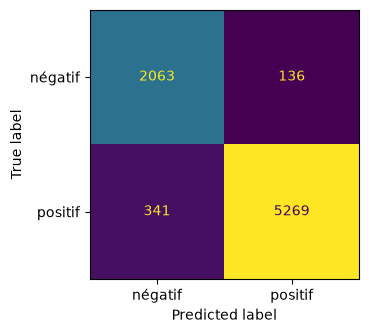

In [8]:
fig, ax = plt.subplots(figsize=(4, 3.5))
ConfusionMatrixDisplay.from_predictions(
    test["label"],
    baseline_proba >= 0.5,
    display_labels=["négatif", "positif"],
    ax=ax,
    colorbar=False,
)
ax.grid(False)
test = test.assign(proba=baseline_proba, error=(baseline_proba >= 0.5) != test["label"])
length_bins = pd.cut(test["words"], [0, 3, 10, 30, 500])
(test.groupby(length_bins, observed=True)["error"].mean() * 100).round(1).to_frame(
    "% d'erreurs"
)

In [9]:
pd.set_option("display.max_colwidth", 120)
false_positive = test[(test["label"] == 0) & (test["proba"] >= 0.5)]
false_negative = test[(test["label"] == 1) & (test["proba"] < 0.5)]
print("Avis NÉGATIFS (note 1-2) prédits positifs, les plus confiants :")
display(false_positive.nlargest(6, "proba")[["review_score", "proba", "text"]])
print("Avis POSITIFS (note 4-5) prédits négatifs, les plus confiants :")
display(false_negative.nsmallest(6, "proba")[["review_score", "proba", "text"]])

Avis NÉGATIFS (note 1-2) prédits positifs, les plus confiants :


,review_score,proba,text
26281,2,0.999790,muito bom gostei do atendimento veio bem antes do prazo
36961,1,0.998971,Recebi o produto muito antes do prazo.Isso é excelente. Muito satisfeito.
18066,1,0.998930,Satisfeito
27306,2,0.998569,Linda.entrega rápida... parabéns
16382,2,0.997765,muito bom.
7177,2,0.997765,Muito bom!


Avis POSITIFS (note 4-5) prédits négatifs, les plus confiants :


,review_score,proba,text
33903,4,0.000159,Produto não chegou
18340,4,0.001126,"Não recebi o produto, enviei mensagem não me responderam, liguei estou esperando até agora o retorno"
8124,4,0.002270,"Muita demora na entrega do produto, vc não consegue rastrear o produto não recomendo a loja."
29658,4,0.002825,Ainda não recebi. Estou aguardando!
28969,5,0.003652,"comprei um tapete mim entregaram outro nao que escolhi, nao compro mais"
26176,5,0.004498,"meu pedido não foi entregue até a presente .\r\nsolicitei 02 jogos de lençois , ok\r\ndois jogos de toalha SÓ VEIO U..."


**Analyse d'erreurs** :

1. **Les erreurs les plus « confiantes » sont du bruit d'étiquette, pas des erreurs du modèle.**
    - « Muito bom! » ou « Recebi muito antes do prazo… excelente » sont notés 1-2/5.
    - « Produto não chegou » ou « Ainda não recebi » sont notés 4-5/5.
    - Le client s'est trompé d'échelle, ou il a noté avant ou après un événement. Le modèle lit correctement le texte.
2. **Les avis longs sont plus difficiles** : on passe de 2,8 % d'erreurs pour 3 mots ou moins à 11,4 % au-delà de 30 mots. Les avis longs mélangent souvent un positif et un négatif (« produto ótimo, mas a entrega atrasou »). Un sac de mots ne capte pas cette structure.
3. **Les fautes et l'argot** (« vc », « mim entregaram ») sont en partie absorbés, car le vocabulaire est appris sur les données réelles.

**Pistes d'amélioration** : une note par aspect (produit, livraison, vendeur) pour les avis longs, et une relecture des avis où le texte contredit la note.

## À retenir

- **Que disent les clients ?** Les avis négatifs parlent surtout de **livraison** : « não recebi », « não chegou », « demora », « esperando ». Viennent ensuite les produits **cassés ou non conformes** (« quebrado », « diferente », « inferior »). Le sentiment rejoint donc la conclusion de l'EDA : **le retard est la première source d'insatisfaction**.
- **Modèle servi** : TF-IDF + régression logistique, avec un F1 macro de 0,93 et **94 % des avis négatifs détectés**.
- **Usage** : trier les nouveaux avis en temps réel, pour que le service client traite les négatifs en premier.
- **Limites** :
    - les étiquettes viennent des notes, qui sont parfois incohérentes avec le texte ;
    - les avis neutres (note 3) sont exclus ;
    - le modèle ne détecte pas l'ironie.